# 03. Social Media Trends Exploration
**Author:** Person 3 (Social Media Trends Data)  
**Project:** Retail Demand Forecasting  

In this notebook, we explore the cleaned Google Trends dataset (`data/processed/trends_clean.csv`).  
Google Trends is used as a stand-in for social media interest (since Twitter/X API access is paid).  
We analyze search trends for three keywords:
- `Drogerie` (Drugstore)
- `Rossmann` (Brand store chain)
- `Angebote` (Special offers / discounts)

We specifically inspect search volume seasonality and check for demand spikes near Christmas / December.

In [1]:
# Import required libraries
import os
import pandas as pd
import matplotlib.pyplot as plt

# Plot configuration for clean visuals
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

## 1. Load Data & Initial Checks
We load `data/processed/trends_clean.csv` and parse the `date` column as a real datetime.

In [2]:
# Locate data file whether executing from repo root or notebooks folder
data_path = "data/processed/trends_clean.csv"
if not os.path.exists(data_path):
    data_path = "../data/processed/trends_clean.csv"

# Load cleaned trends data and parse dates
df = pd.read_csv(data_path, parse_dates=["date"])

# 1. Print shape
print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")

# 2. Check for missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# 3. Preview first 5 rows
print("\nFirst 5 rows:")
df.head()

Dataset shape: 135 rows, 4 columns

Missing values per column:
date              0
trend_drogerie    0
trend_rossmann    0
trend_angebote    0
dtype: int64

First 5 rows:


,date,trend_drogerie,trend_rossmann,trend_angebote
0,2012-12-30,58,61,65
1,2013-01-06,58,64,60
2,2013-01-13,58,52,54
3,2013-01-20,59,57,55
4,2013-01-27,68,49,58


## 2. Keyword Trends Over Time & Christmas Seasonality
We plot each keyword individually over time.
To check for holiday seasonality, we highlight the December / Christmas period:
- **Red shaded region:** December (Holiday shopping season)
- **Red dashed vertical line:** Christmas Day (December 25)

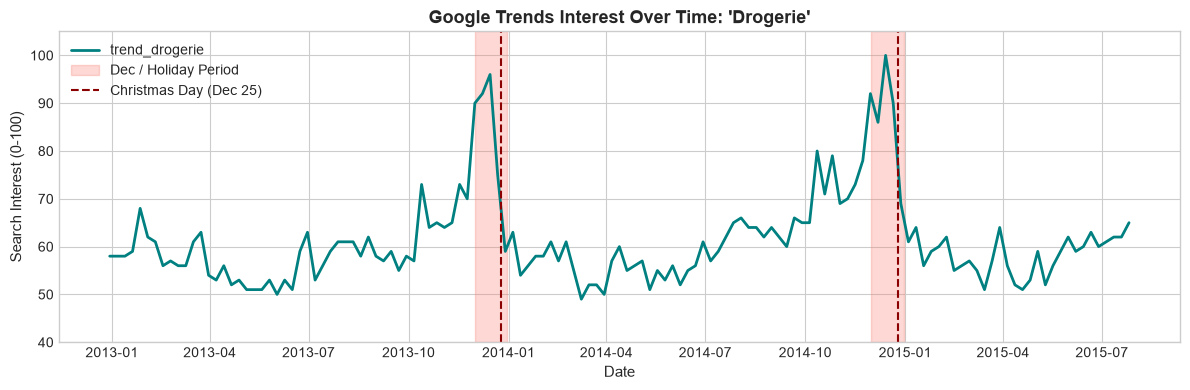

In [3]:
# Chart 1: Drogerie Search Interest Over Time
plt.figure(figsize=(12, 4))
plt.plot(df["date"], df["trend_drogerie"], color="teal", linewidth=2, label="trend_drogerie")

# Highlight December / Christmas periods
plt.axvspan(pd.to_datetime("2013-12-01"), pd.to_datetime("2013-12-31"), color="salmon", alpha=0.3, label="Dec / Holiday Period")
plt.axvspan(pd.to_datetime("2014-12-01"), pd.to_datetime("2014-12-31"), color="salmon", alpha=0.3)
plt.axvline(pd.to_datetime("2013-12-25"), color="darkred", linestyle="--", linewidth=1.5, label="Christmas Day (Dec 25)")
plt.axvline(pd.to_datetime("2014-12-25"), color="darkred", linestyle="--", linewidth=1.5)

plt.title("Google Trends Interest Over Time: 'Drogerie'", fontsize=13, fontweight="bold")
plt.xlabel("Date", fontsize=11)
plt.ylabel("Search Interest (0-100)", fontsize=11)
plt.ylim(40, 105)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

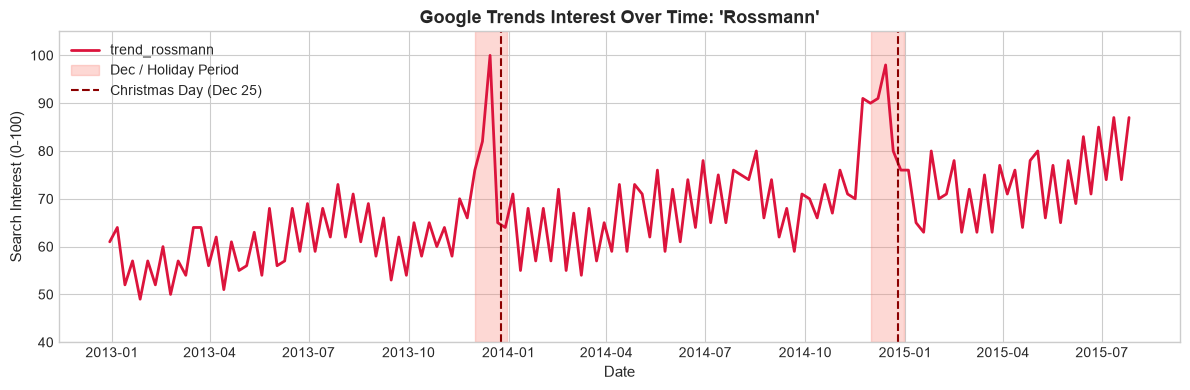

In [4]:
# Chart 2: Rossmann Search Interest Over Time
plt.figure(figsize=(12, 4))
plt.plot(df["date"], df["trend_rossmann"], color="crimson", linewidth=2, label="trend_rossmann")

# Highlight December / Christmas periods
plt.axvspan(pd.to_datetime("2013-12-01"), pd.to_datetime("2013-12-31"), color="salmon", alpha=0.3, label="Dec / Holiday Period")
plt.axvspan(pd.to_datetime("2014-12-01"), pd.to_datetime("2014-12-31"), color="salmon", alpha=0.3)
plt.axvline(pd.to_datetime("2013-12-25"), color="darkred", linestyle="--", linewidth=1.5, label="Christmas Day (Dec 25)")
plt.axvline(pd.to_datetime("2014-12-25"), color="darkred", linestyle="--", linewidth=1.5)

plt.title("Google Trends Interest Over Time: 'Rossmann'", fontsize=13, fontweight="bold")
plt.xlabel("Date", fontsize=11)
plt.ylabel("Search Interest (0-100)", fontsize=11)
plt.ylim(40, 105)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

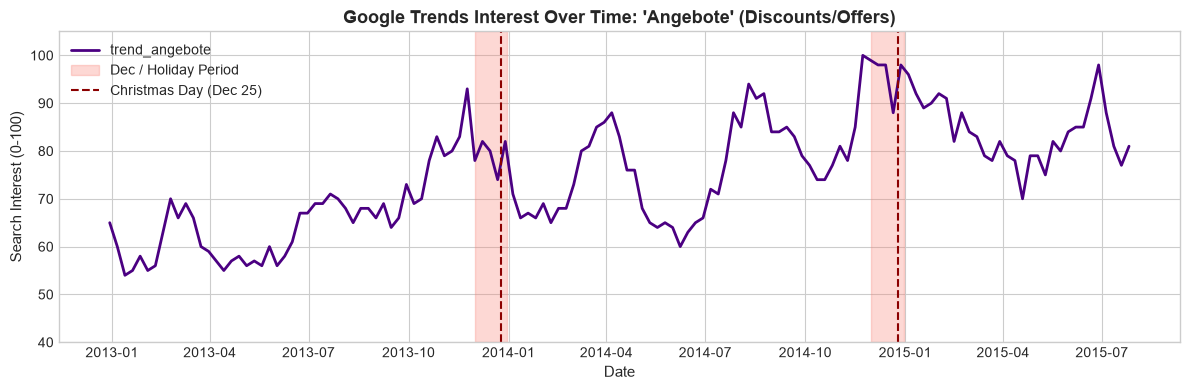

In [5]:
# Chart 3: Angebote Search Interest Over Time
plt.figure(figsize=(12, 4))
plt.plot(df["date"], df["trend_angebote"], color="indigo", linewidth=2, label="trend_angebote")

# Highlight December / Christmas periods
plt.axvspan(pd.to_datetime("2013-12-01"), pd.to_datetime("2013-12-31"), color="salmon", alpha=0.3, label="Dec / Holiday Period")
plt.axvspan(pd.to_datetime("2014-12-01"), pd.to_datetime("2014-12-31"), color="salmon", alpha=0.3)
plt.axvline(pd.to_datetime("2013-12-25"), color="darkred", linestyle="--", linewidth=1.5, label="Christmas Day (Dec 25)")
plt.axvline(pd.to_datetime("2014-12-25"), color="darkred", linestyle="--", linewidth=1.5)

plt.title("Google Trends Interest Over Time: 'Angebote' (Discounts/Offers)", fontsize=13, fontweight="bold")
plt.xlabel("Date", fontsize=11)
plt.ylabel("Search Interest (0-100)", fontsize=11)
plt.ylim(40, 105)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 3. Analysis: Do Spikes Occur Near Christmas?

**Yes, the charts show clear and significant spikes near Christmas across all three keywords:**

1. **`trend_drogerie`**: Reaches its highest points of the year in mid-December (surging to **96** in mid-December 2013 and peaking at the maximum **100** in mid-December 2014). This possibly reflects seasonal customer demand for drugstore gift items, perfumes, and holiday personal care products right before Christmas.
2. **`trend_rossmann`**: Demonstrates distinct holiday surges directly preceding Christmas, reaching **100** (the all-time peak for the series) on December 15, 2013, and **98** on December 14, 2014. Interest drops back down immediately after Christmas week.
3. **`trend_angebote` (Discounts / Offers)**: Spikes sharply in late November (**93** on 2013-11-24 and **100** on 2014-11-23), which may be related to Black Friday / Cyber Week promotions, and stays consistently high throughout December (around **80-98**).

**Conclusion:** Search trends provide a seasonal pattern that may help the forecasting model, which we will test.